# Fakeddit Multimodal Misinformation Detection
### Stage 4 — Uncertainty Analysis & Per-Class Calibration

**Why this notebook exists:** Stage 3 found that the fusion model is the most accurate but least calibrated of the three models, high aggregate ECE. But aggregate ECE is a single number averaged across all three classes, and Stage 1 already flagged that the rare satire class (~2-3% of the data) barely influences that average. This notebook answers the question directly: **where specifically is the fusion model overconfident, is it spread evenly, or concentrated on the class it sees the least?**

**This notebook covers:**
1. Load the fusion model and shared test set from Stage 3
2. **Per-class ECE**, calibration computed separately for each of the three classes, not averaged together
3. **Confidently-wrong vs. genuinely-uncertain case analysis**, separating "the model was sure and got it wrong" (the dangerous failure mode) from "the model was unsure and got it wrong" (the honest failure mode)
4. A worked example: pull out a handful of the most confidently-wrong cases for Stage 5's explainability work

## Step 0 — Setup

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, json
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt

DRIVE_ROOT = '/content/drive/MyDrive/fakeddit_calibration'
LABEL_COL = '3_way_label'
LABEL_NAMES = {0: 'Real', 1: 'Satire', 2: 'Misleading'}   # Fakeddit 3-way label convention — verify against your TSV if unsure
SEED = 42

print(f"Drive root: {DRIVE_ROOT}")


Mounted at /content/drive
Drive root: /content/drive/MyDrive/fakeddit_calibration


## Step 1 — Load the fusion model, shared split, and embeddings from Stages 2–3




In [ ]:
splits_dir = f'{DRIVE_ROOT}/metadata/splits_multimodal'
test_df = pd.read_csv(f'{splits_dir}/test.csv')

clip_cache = np.load(f'{DRIVE_ROOT}/embeddings/clip_image_embeddings.npz', allow_pickle=True)
id_to_clip = dict(zip(clip_cache['ids'].tolist(), clip_cache['embeddings']))

text_test_emb = np.load(f'{DRIVE_ROOT}/embeddings/roberta_multimodal_test.npy')
id_to_text_test = dict(zip(test_df['id'], text_test_emb))

X_text_test = np.stack([id_to_text_test[i] for i in test_df['id']])
X_image_test = np.stack([id_to_clip[i] for i in test_df['id']])
X_fusion_test = np.concatenate([X_text_test, X_image_test], axis=1)
y_test = test_df[LABEL_COL].values

fusion_model = joblib.load(f'{DRIVE_ROOT}/models/fusion_shared_split.joblib')

y_pred = fusion_model.predict(X_fusion_test)
y_proba = fusion_model.predict_proba(X_fusion_test)
confidences = np.max(y_proba, axis=1)

print(f"Test set: {len(y_test)} examples")
print(f"Overall accuracy: {(y_pred == y_test).mean():.4f}")


Test set: 2986 examples
Overall accuracy: 0.8282


In [ ]:
# Sanity check: pulling a few examples from each label and eyeball whether the text matches the expected category
for label_val, label_name in LABEL_NAMES.items():
    print(f"\n--- Label {label_val} ({label_name}) — sample titles ---")
    examples = test_df[test_df[LABEL_COL] == label_val]['clean_title'].head(3)
    for t in examples:
        print(f"  • {t}")


--- Label 0 (Real) — sample titles ---
  • my mother on a camel
  • a snail on a new orleans shop window
  • this crosswalk in the canadian surf capital tofino comes with its very own wave

--- Label 1 (Satire) — sample titles ---
  • from the local bomb factory us modern
  • found an old postcard lenin in zakopane
  • everyone agrees with this statement newfoundland

--- Label 2 (Misleading) — sample titles ---
  • happy jeep is happy
  • american revolution propoganda
  • this eye watches me when i visit my moms


## Step 2 — Per-class ECE

Same ECE formula as before, but computed separately within each true class rather than across all test examples pooled together. This directly tests the hypothesis flagged since Stage 1: that aggregate calibration metrics are hiding much worse calibration on the rare satire class.


In [ ]:
def compute_ece(y_true_subset, y_proba_subset, n_bins=10):
    confidences_subset = np.max(y_proba_subset, axis=1)
    predictions_subset = np.argmax(y_proba_subset, axis=1)
    accuracies_subset = (predictions_subset == y_true_subset).astype(float)

    bin_edges = np.linspace(0, 1, n_bins + 1)
    ece = 0.0
    bin_stats = []
    for i in range(n_bins):
        lo, hi = bin_edges[i], bin_edges[i + 1]
        in_bin = (confidences_subset > lo) & (confidences_subset <= hi)
        prop_in_bin = in_bin.mean()
        if prop_in_bin > 0:
            acc_in_bin = accuracies_subset[in_bin].mean()
            conf_in_bin = confidences_subset[in_bin].mean()
            ece += np.abs(acc_in_bin - conf_in_bin) * prop_in_bin
            bin_stats.append({'bin_range': [float(round(lo, 2)), float(round(hi, 2))],
                               'accuracy': float(acc_in_bin), 'confidence': float(conf_in_bin),
                               'proportion': float(prop_in_bin)})
    return float(ece), bin_stats

SUMMARY_PATH = f'{DRIVE_ROOT}/metadata/uncertainty_analysis_summary.json'

if os.path.exists(SUMMARY_PATH):
    print("Cached results found — loading instead of recomputing.\n")
    with open(SUMMARY_PATH) as f:
        uncertainty_summary = json.load(f)
    per_class_ece = uncertainty_summary['per_class_ece']
else:
    print("No cached results — computing per-class ECE now.\n")
    per_class_ece = {}
    for class_idx, class_name in LABEL_NAMES.items():
        mask = (y_test == class_idx)
        n_examples = int(mask.sum())
        if n_examples == 0:
            continue
        # NOTE: ECE is normally computed over ALL predictions, checking whether the model's confidence matches its accuracy WHEN IT PREDICTS that class's examples correctly.
        # Here we condition on the true class to see: "when the true answer is class X, how well-calibrated is the model's confidence in its (possibly wrong) prediction?"
        class_ece, class_bins = compute_ece(y_test[mask], y_proba[mask], n_bins=10)
        per_class_ece[class_name] = {
            'n_test_examples': n_examples,
            'ece': round(class_ece, 4),
            'accuracy': round(float((y_pred[mask] == y_test[mask]).mean()), 4),
            'mean_confidence': round(float(confidences[mask].mean()), 4),
            'calibration_bins': class_bins,
        }
    uncertainty_summary = {'per_class_ece': per_class_ece}

print(f"{'Class':<12}{'N (test)':<10}{'Accuracy':<10}{'Mean Conf.':<12}{'ECE':<8}")
for name, stats in per_class_ece.items():
    print(f"{name:<12}{stats['n_test_examples']:<10}{stats['accuracy']:<10}{stats['mean_confidence']:<12}{stats['ece']:<8}")


No cached results — computing per-class ECE now.

Class       N (test)  Accuracy  Mean Conf.  ECE     
Real        1639      0.8609    0.875       0.0269  
Satire      107       0.8692    0.9408      0.0899  
Misleading  1240      0.7815    0.8771      0.0959  


## Step 3 — Confidently-wrong vs. genuinely-uncertain cases

Two very different kinds of mistake:
- **Confidently wrong:** the model predicted with high confidence (e.g. >0.8) and was still incorrect, the dangerous failure mode, since a human reviewer would have no reason to double-check these.
- **Genuinely uncertain:** the model's top confidence was low (e.g. <0.5), an "honest" mistake, since the model itself is signaling it isn't sure.

The ratio between these two groups is itself a calibration signal: a well-calibrated model's mistakes should skew toward the uncertain end.


In [ ]:
wrong_mask = (y_pred != y_test)
n_wrong = wrong_mask.sum()

confidently_wrong_mask = wrong_mask & (confidences > 0.8)
uncertain_wrong_mask = wrong_mask & (confidences < 0.5)
mid_confidence_wrong_mask = wrong_mask & (confidences >= 0.5) & (confidences <= 0.8)

n_confidently_wrong = int(confidently_wrong_mask.sum())
n_uncertain_wrong = int(uncertain_wrong_mask.sum())
n_mid_wrong = int(mid_confidence_wrong_mask.sum())

print(f"Total incorrect predictions: {n_wrong} / {len(y_test)} ({n_wrong/len(y_test):.1%})")
print(f"\n  Confidently wrong (conf > 0.8): {n_confidently_wrong} ({n_confidently_wrong/n_wrong:.1%} of all mistakes)")
print(f"  Mid-confidence wrong (0.5-0.8): {n_mid_wrong} ({n_mid_wrong/n_wrong:.1%} of all mistakes)")
print(f"  Genuinely uncertain (conf < 0.5): {n_uncertain_wrong} ({n_uncertain_wrong/n_wrong:.1%} of all mistakes)")

print(f"\nBreakdown of confidently-wrong cases by true class:")
if n_confidently_wrong > 0:
    cw_true_classes = test_df.loc[confidently_wrong_mask, LABEL_COL].map(LABEL_NAMES)
    print(cw_true_classes.value_counts())


Total incorrect predictions: 513 / 2986 (17.2%)

  Confidently wrong (conf > 0.8): 223 (43.5% of all mistakes)
  Mid-confidence wrong (0.5-0.8): 285 (55.6% of all mistakes)
  Genuinely uncertain (conf < 0.5): 5 (1.0% of all mistakes)

Breakdown of confidently-wrong cases by true class:
3_way_label
Misleading    128
Real           86
Satire          9
Name: count, dtype: int64


## Step 4 — Pull concrete examples for the write-up and Stage 5

Save the actual post IDs and text of the most confidently-wrong cases, these are exactly the examples worth running SHAP/Grad-CAM on in Stage 5, since they're the cases where explainability has the most to reveal.


In [ ]:
confidently_wrong_examples = test_df.loc[confidently_wrong_mask, ['id', 'clean_title', LABEL_COL]].copy()
confidently_wrong_examples['predicted_label'] = y_pred[confidently_wrong_mask]
confidently_wrong_examples['confidence'] = confidences[confidently_wrong_mask]
confidently_wrong_examples['true_label_name'] = confidently_wrong_examples[LABEL_COL].map(LABEL_NAMES)
confidently_wrong_examples['predicted_label_name'] = confidently_wrong_examples['predicted_label'].map(LABEL_NAMES)
confidently_wrong_examples = confidently_wrong_examples.sort_values('confidence', ascending=False)

examples_path = f'{DRIVE_ROOT}/metadata/confidently_wrong_examples.csv'
confidently_wrong_examples.to_csv(examples_path, index=False)

print(f"Saved {len(confidently_wrong_examples)} confidently-wrong examples -> {examples_path}\n")
print(confidently_wrong_examples[['clean_title', 'true_label_name', 'predicted_label_name', 'confidence']].head(10).to_string(index=False))


Saved 223 confidently-wrong examples -> /content/drive/MyDrive/fakeddit_calibration/metadata/confidently_wrong_examples.csv

                                                                                                                                                    clean_title true_label_name predicted_label_name  confidence
                                                                                                              the bottom of our loaf of bread was smiling at me            Real           Misleading    0.999536
                                                                                                                                             the sad tub is sad            Real           Misleading    0.999226
this isnt a poster but the rules allow for any this is a song called the sacred war sung by the red army in the defense of moscow in english subtitles included          Satire           Misleading    0.999198
                                       

## Step 5 — Save summary and a comparison chart

Saved -> /content/drive/MyDrive/fakeddit_calibration/metadata/uncertainty_analysis_summary.json


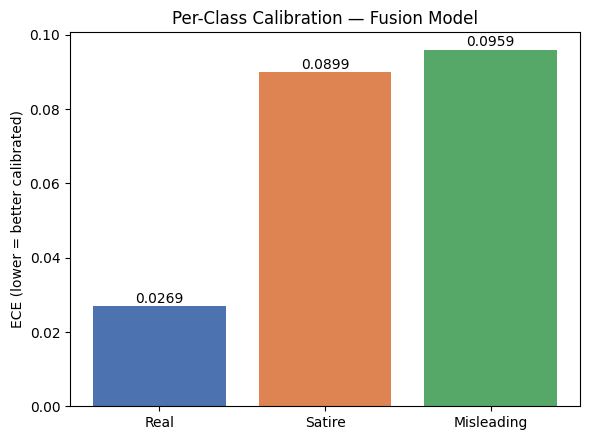

In [ ]:
if not os.path.exists(SUMMARY_PATH):
    uncertainty_summary.update({
        'seed': SEED,
        'n_test': len(y_test),
        'overall_accuracy': round(float((y_pred == y_test).mean()), 4),
        'mistake_breakdown': {
            'total_mistakes': int(n_wrong),
            'confidently_wrong': n_confidently_wrong,
            'mid_confidence_wrong': n_mid_wrong,
            'genuinely_uncertain_wrong': n_uncertain_wrong,
        },
    })
    with open(SUMMARY_PATH, 'w') as f:
        json.dump(uncertainty_summary, f, indent=2)
    print(f"Saved -> {SUMMARY_PATH}")
else:
    print("Summary already cached — not overwritten.")

# Simple bar chart: per-class ECE, easy to drop straight into a write-up or slide
fig, ax = plt.subplots(figsize=(6, 4.5))
names = list(per_class_ece.keys())
eces = [per_class_ece[n]['ece'] for n in names]
ax.bar(names, eces, color=['#4C72B0', '#DD8452', '#55A868'])
ax.set_ylabel('ECE (lower = better calibrated)')
ax.set_title('Per-Class Calibration — Fusion Model')
for i, v in enumerate(eces):
    ax.text(i, v + 0.001, f'{v:.4f}', ha='center')
plt.tight_layout()
plt.savefig(f'{DRIVE_ROOT}/figures/per_class_ece_comparison.png', dpi=150)
plt.show()
